# One-page checkout A/B test: walkthrough

The same analysis as `src/`, step by step. Run `run_all.sh` first (it generates the data).

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from src.analyze import conversion_test

df = pd.read_csv('../data/users.csv', parse_dates=['date'])
plan = json.load(open('../results/plan.json'))
print(f"{len(df):,} users, {df['date'].nunique()} days; planned {plan['n_per_arm']:,} per arm")
df.head()

97,867 users, 28 days; planned 45,338 per arm


,user_id,date,arm,device,user_type,converted,revenue
0,1,2026-03-02,control,mobile,new,0,0.0
1,2,2026-03-02,treatment,mobile,new,0,0.0
2,3,2026-03-02,control,desktop,new,0,0.0
3,4,2026-03-02,treatment,mobile,new,0,0.0
4,5,2026-03-02,control,mobile,returning,0,0.0


## 1. Validity: sample ratio and balance

In [2]:
counts = df['arm'].value_counts()
print(counts)
print('SRM chi-square p =', round(stats.chisquare(counts.values).pvalue, 3))
pd.crosstab(df['arm'], [df['device'], df['user_type']], normalize='index').round(3)

arm
control      49082
treatment    48785
Name: count, dtype: int64
SRM chi-square p = 0.342


device    desktop           mobile          
user_type     new returning    new returning
arm                                         
control     0.189     0.230  0.261     0.320
treatment   0.190     0.234  0.258     0.319

## 2. Primary metric: conversion

In [3]:
c, t = df[df['arm'] == 'control'], df[df['arm'] == 'treatment']
r = conversion_test(c, t)
print(f"control {r['control']:.3%}  treatment {r['treatment']:.3%}  lift {r['lift']:+.1%}  "
      f"95% CI {r['lift_ci'][0]:+.1%} to {r['lift_ci'][1]:+.1%}  p = {r['p']:.3f}")

control 3.494%  treatment 3.710%  lift +6.2%  95% CI -0.5% to +12.9%  p = 0.070


## 3. Revenue: per user and per buyer

Most users spend nothing, so revenue per user is very skewed; the bootstrap interval does not lean on normality.

In [4]:
df.groupby('arm').agg(users=('user_id', 'size'), buyers=('converted', 'sum'),
                    revenue_per_user=('revenue', 'mean'),
                    order_value=('revenue', lambda s: s[s > 0].mean())).round(3)

,users,buyers,revenue_per_user,order_value
arm,,,,
control,49082,1715,2.137,61.153
treatment,48785,1810,2.183,58.830


## 4. Segments

Four cuts, so p-values get a Holm correction before anything is called a finding.

In [5]:
pd.read_csv('../results/segments.csv')

,segment,users,control,treatment,lift,lift_lo,lift_hi,p,p_holm
0,device=desktop,41248,0.04481,0.04480,-0.00026,-0.08945,0.08892,0.99544,1.00000
1,device=mobile,56619,0.02781,0.03145,0.13121,0.03075,0.23189,0.01046,0.04184
2,user_type=new,43912,0.02585,0.02511,-0.02841,-0.14260,0.08582,0.62544,1.00000
3,user_type=returning,53955,0.04238,0.04680,0.10425,0.02206,0.18652,0.01291,0.04184


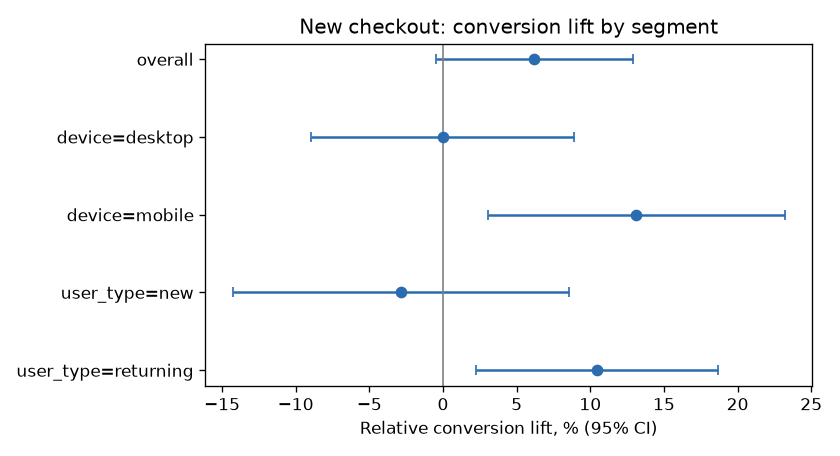

In [6]:
from IPython.display import Image, display
display(Image('../results/lift_by_segment.png'))

## 5. Cumulative readout by day

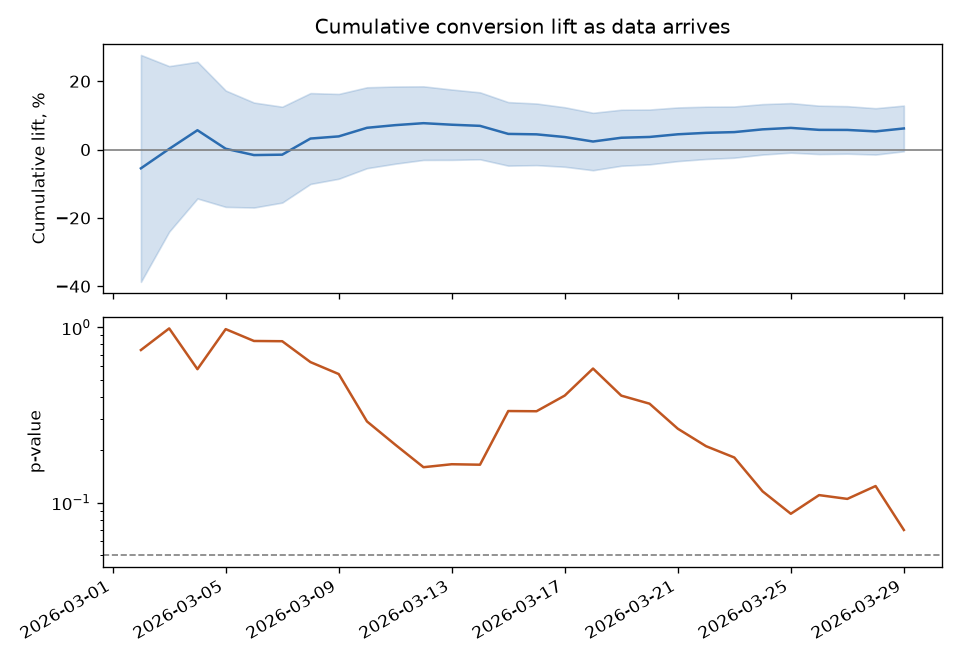

,date,users,lift,lift_lo,lift_hi,p
21,2026-03-23,76816,0.05111,-0.02378,0.12603,0.18092
22,2026-03-24,80285,0.05916,-0.01462,0.13298,0.11598
23,2026-03-25,83845,0.06341,-0.00908,0.13595,0.08637
24,2026-03-26,87363,0.05766,-0.01314,0.12852,0.11037
25,2026-03-27,90894,0.05746,-0.01203,0.12700,0.10501
26,2026-03-28,94384,0.05317,-0.01465,0.12103,0.12433
27,2026-03-29,97867,0.06182,-0.00501,0.12870,0.06980


In [7]:
display(Image('../results/cumulative.png'))
pd.read_csv('../results/daily.csv').tail(7)

## 6. Decision

In [8]:
m = json.load(open('../results/metrics.json'))
print('Decision:', m['decision'])

Decision: do not ship
